In [0]:
%pip install nltk wordcloud

import re
from collections import Counter
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import twitter_samples
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from wordcloud import STOPWORDS, WordCloud

# Ensure NLTK datasets are downloaded
try:
    nltk.data.find("corpora/twitter_samples")
    nltk.data.find("sentiment/vader_lexicon.zip")
except LookupError:
    nltk.download("twitter_samples")
    nltk.download("vader_lexicon")

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


[nltk_data] Downloading package twitter_samples to
[nltk_data]     /home/spark-1bbd5e47-fd98-45a7-8b87-78/nltk_data...
[nltk_data]   Unzipping corpora/twitter_samples.zip.
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /home/spark-1bbd5e47-fd98-45a7-8b87-78/nltk_data...


In [0]:
# Exercise 1: Word Cloud Generation
# Sample Data Science Corpus
sample_text = """
Data science is an interdisciplinary academic field that uses statistics, scientific computing, 
scientific methods, processes, algorithms and systems to extract or extrapolate knowledge and 
insights from noisy, structured, and unstructured data. Data science integrates domain knowledge 
from the underlying application domain (e.g., natural sciences, information technology, and medicine). 
Machine learning algorithms and predictive analytics are often said to be using deep learning models 
that would transform raw data into actionable decision-making insights. Using advanced analytics, 
practitioners extract valuable patterns, using statistical models and artificial intelligence.
"""

In [0]:
# Basic Word Cloud Implementation
# 1. Initialize WordCloud object with basic styling parameters
basic_wc = WordCloud(
    width=800,
    height=800,
    background_color="white",
    min_font_size=10,
    colormap="viridis",
).generate(sample_text)

# 2. Display the word cloud using matplotlib
plt.figure(figsize=(8, 8), facecolor=None)
plt.imshow(basic_wc, interpolation="bilinear")
plt.axis("off")
plt.tight_layout(pad=0)
plt.title("Basic Data Science Word Cloud", fontsize=16, pad=20)
plt.savefig("basic_wordcloud.png", format="png", dpi=300)
plt.show()

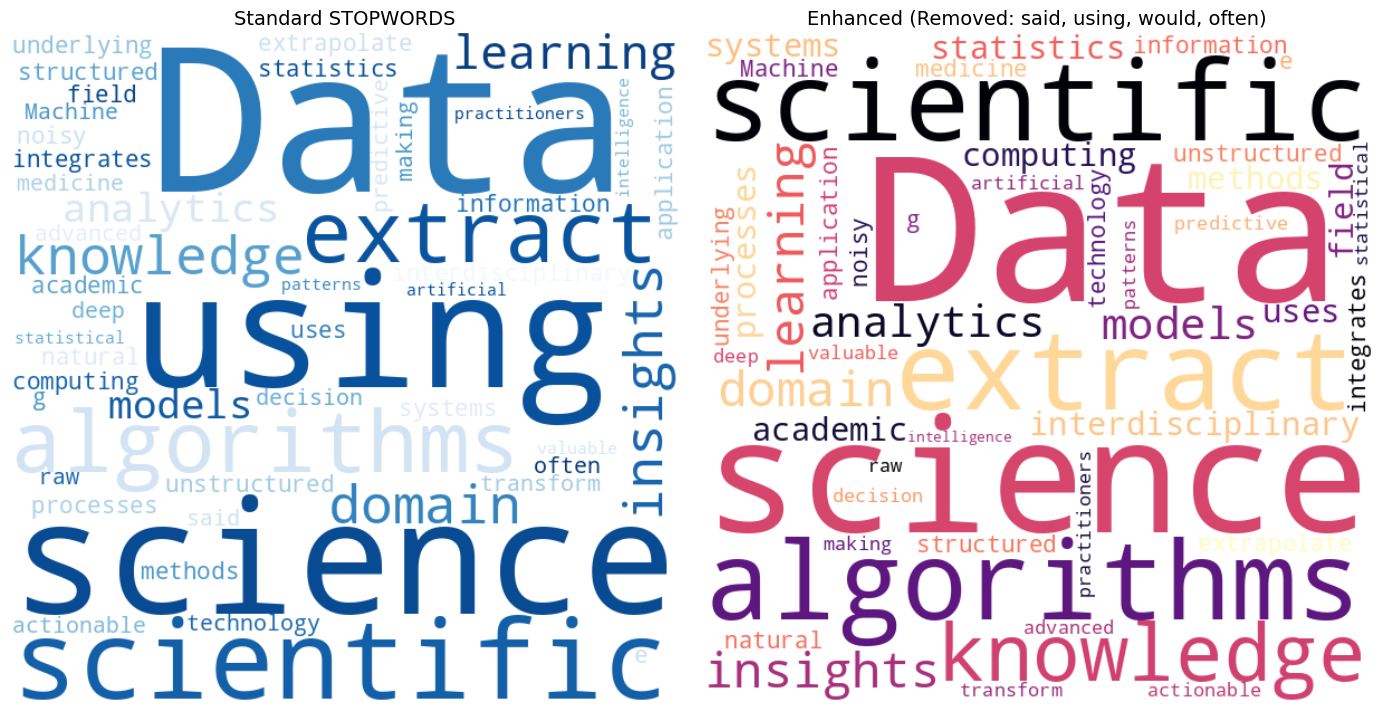

In [0]:
# Question 1: Custom Stop Words Comparison
def compare_wordclouds_with_stopwords(
    text: str, custom_stops: list[str] = None
) -> None:
    """Generates and displays side-by-side word clouds comparing default STOPWORDS

    against a merged set of default and custom stopwords.
    """
    custom_stops = custom_stops or []

    # Combine default wordcloud STOPWORDS with custom additions
    combined_stopwords = STOPWORDS.union(set(custom_stops))

    # Generate standard word cloud
    wc_original = WordCloud(
        width=600,
        height=600,
        background_color="white",
        stopwords=STOPWORDS,
        colormap="Blues",
    ).generate(text)

    # Generate enhanced word cloud with custom stopwords
    wc_filtered = WordCloud(
        width=600,
        height=600,
        background_color="white",
        stopwords=combined_stopwords,
        colormap="magma",
    ).generate(text)

    # Plot side-by-side subplots
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))

    axes[0].imshow(wc_original, interpolation="bilinear")
    axes[0].set_title("Standard STOPWORDS", fontsize=14)
    axes[0].axis("off")

    axes[1].imshow(wc_filtered, interpolation="bilinear")
    axes[1].set_title(
        f"Enhanced (Removed: {', '.join(custom_stops)})", fontsize=14
    )
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()


# Example usage:
custom_stop_list = ["said", "using", "would", "often"]
compare_wordclouds_with_stopwords(sample_text, custom_stops=custom_stop_list)

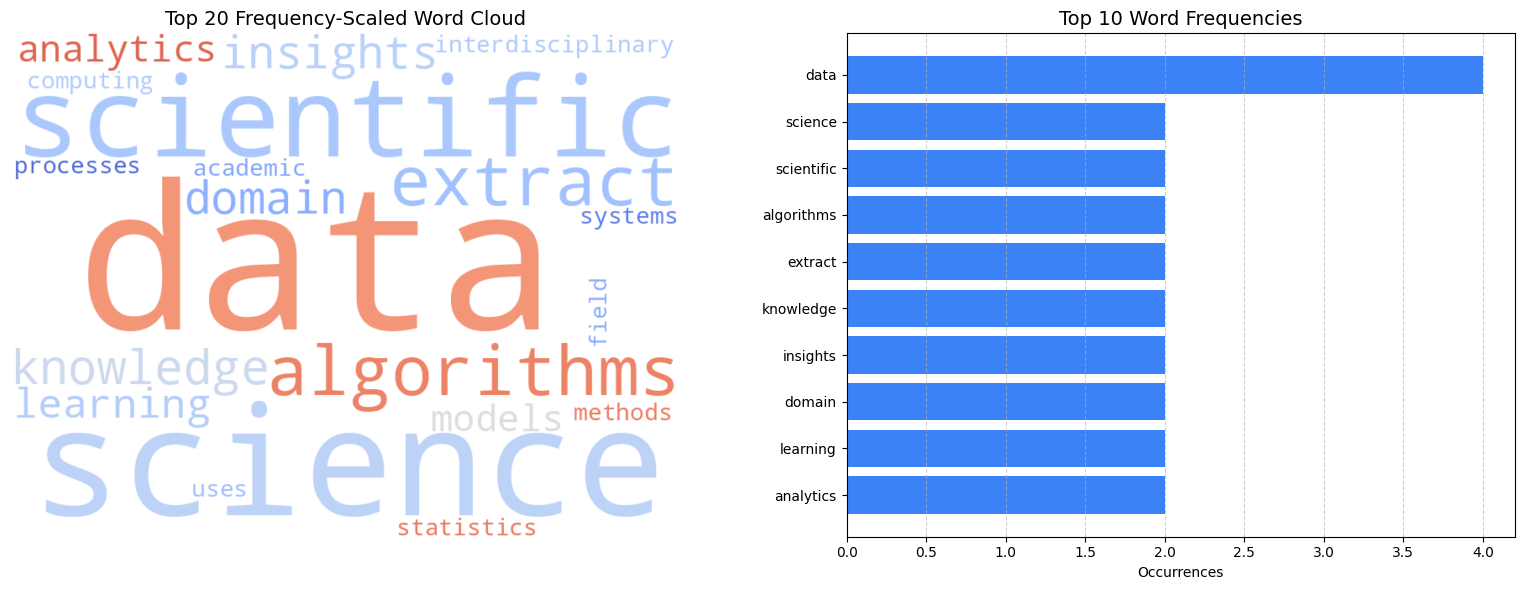

In [0]:
# Question 2: Frequency-Based Word Cloud
def generate_frequency_wordcloud(
    text: str, top_n: int = 50, min_word_length: int = 3
) -> Counter:
    """Tokenizes text, filters stopwords/short tokens, counts word frequencies,

    and displays both a ranked bar chart and a frequency-scaled word cloud.
    """
    # Tokenize using regex to extract clean words
    tokens = re.findall(r"\b[a-zA-Z]+\b", text.lower())

    # Build comprehensive exclusion list
    extended_stops = STOPWORDS.union({"using", "said", "would"})

    # Filter by stopword set and token length threshold
    filtered_tokens = [
        word
        for word in tokens
        if word not in extended_stops and len(word) >= min_word_length
    ]

    # Compute frequency distribution
    word_counts = Counter(filtered_tokens)
    top_words = dict(word_counts.most_common(top_n))

    # Generate cloud scaled directly to frequencies
    wc_freq = WordCloud(
        width=800,
        height=600,
        background_color="white",
        colormap="coolwarm",
    ).generate_from_frequencies(top_words)

    # Visualization: Word Cloud + Frequency Bar Chart
    fig, (ax_wc, ax_bar) = plt.subplots(
        1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.2, 1]}
    )

    ax_wc.imshow(wc_freq, interpolation="bilinear")
    ax_wc.axis("off")
    ax_wc.set_title(f"Top {top_n} Frequency-Scaled Word Cloud", fontsize=14)

    # Plot top 10 for bar chart scannability
    top_10 = word_counts.most_common(10)
    words, freqs = zip(*top_10)

    ax_bar.barh(words[::-1], freqs[::-1], color="#3b82f6")
    ax_bar.set_xlabel("Occurrences")
    ax_bar.set_title("Top 10 Word Frequencies", fontsize=14)
    ax_bar.grid(axis="x", linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.show()

    return word_counts


# Example usage:
word_frequencies = generate_frequency_wordcloud(sample_text, top_n=20)

In [0]:
# Exercise 2: Social Media Sentiment Analysis
# Basic Sentiment Implementation

def load_vader_analyzer() -> SentimentIntensityAnalyzer:
    """Initializes VADER SentimentIntensityAnalyzer with safety handling."""
    try:
        return SentimentIntensityAnalyzer()
    except LookupError:
        nltk.download("vader_lexicon")
        return SentimentIntensityAnalyzer()


sia = load_vader_analyzer()

# Load Twitter corpora
pos_tweets = twitter_samples.strings("positive_tweets.json")
neg_tweets = twitter_samples.strings("negative_tweets.json")

# Sample demonstration
sample_subset = [pos_tweets[0], neg_tweets[0]]
for tweet in sample_subset:
    scores = sia.polarity_scores(tweet)
    print(f"Tweet: {tweet}")
    print(f"Scores -> Compound: {scores['compound']}, Full: {scores}\n")

Tweet: #FollowFriday @France_Inte @PKuchly57 @Milipol_Paris for being top engaged members in my community this week :)
Scores -> Compound: 0.7579, Full: {'neg': 0.0, 'neu': 0.615, 'pos': 0.385, 'compound': 0.7579}

Tweet: hopeless for tmr :(
Scores -> Compound: -0.7096, Full: {'neg': 0.747, 'neu': 0.253, 'pos': 0.0, 'compound': -0.7096}



============================== MOST POSITIVE TWEETS ==============================
#1 [Compound: 0.9661] | @Michael5SOS good night lovely, I hope you have a peaceful nights rest, and feel refreshed when you wake up, sweet dreams :)
#2 [Compound: 0.9575] | BIG thx @bikechainricci 4 the kind support @SHINEUKCharity @ShineBalloons. GOOD LUCK!! :-)
#3 [Compound: 0.9545] | #JUMMA_MUBARIK &lt;3 &lt;3 &lt;3 
to aLL #FrNds  :* 
          #StaY_BlesseD :) :) :* — feeling blessed

============================== MOST NEGATIVE TWEETS ==============================
#1 [Compound: -0.9325] | What the hell is going wrong :( I don't understand why people choose to hurt each other https://t.co/hIBjz4fC2r
#2 [Compound: -0.9231] | 3:30am walk down Inglewood ummm bad idea :( ugh stupid anxiety
#3 [Compound: -0.9186] | @mustntgrumble I hadn't thought of an icepack. Big doses of pain killers on board. But it is feeling very very painful already :( *whimpers*


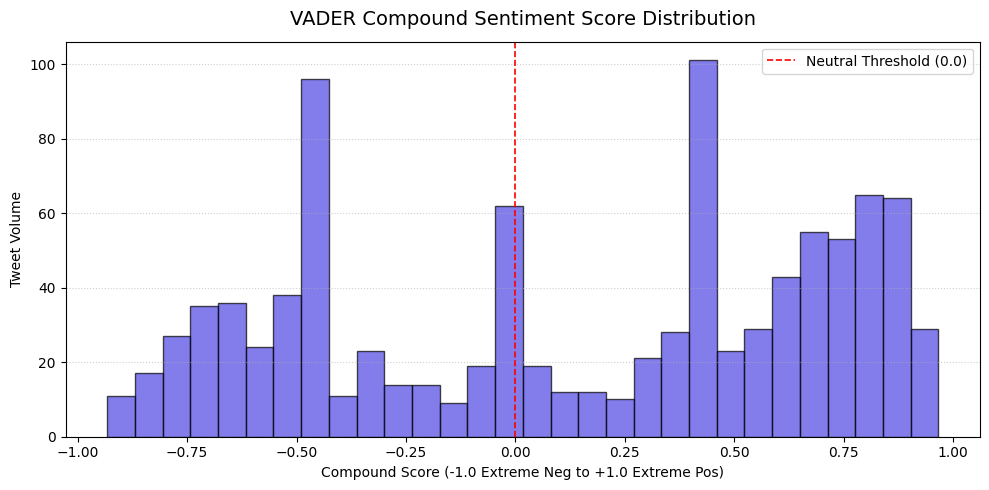

In [0]:
# Question 3: Extreme Sentiment Analysis & Score Distribution
def analyze_tweet_corpus(
    tweets: list[str], analyzer: SentimentIntensityAnalyzer
) -> list[dict]:
    """Scores a collection of tweets and structures metrics into structured dictionaries."""
    results = []
    for tweet in tweets:
        polarity = analyzer.polarity_scores(tweet)
        results.append(
            {
                "text": tweet,
                "compound": polarity["compound"],
                "pos": polarity["pos"],
                "neg": polarity["neg"],
                "neu": polarity["neu"],
            }
        )
    return results


def display_extreme_tweets(analyzed_data: list[dict], n: int = 3) -> None:
    """Sorts analyzed corpus by compound score to isolate extremes."""
    # Sort descending for extreme positive, ascending for extreme negative
    sorted_by_compound = sorted(
        analyzed_data, key=lambda item: item["compound"]
    )

    most_negative = sorted_by_compound[:n]
    most_positive = sorted_by_compound[-n:][::-1]

    print(f"{'='*30} MOST POSITIVE TWEETS {'='*30}")
    for rank, entry in enumerate(most_positive, 1):
        print(f"#{rank} [Compound: {entry['compound']:.4f}] | {entry['text']}")

    print(f"\n{'='*30} MOST NEGATIVE TWEETS {'='*30}")
    for rank, entry in enumerate(most_negative, 1):
        print(f"#{rank} [Compound: {entry['compound']:.4f}] | {entry['text']}")


def plot_sentiment_distribution(analyzed_data: list[dict]) -> None:
    """Renders a labeled histogram showing the distribution of compound polarity scores."""
    compounds = [d["compound"] for d in analyzed_data]

    plt.figure(figsize=(10, 5))
    plt.hist(compounds, bins=30, color="#4f46e5", edgecolor="black", alpha=0.7)
    plt.axvline(
        0.0,
        color="red",
        linestyle="--",
        linewidth=1.2,
        label="Neutral Threshold (0.0)",
    )

    plt.title(
        "VADER Compound Sentiment Score Distribution", fontsize=14, pad=12
    )
    plt.xlabel("Compound Score (-1.0 Extreme Neg to +1.0 Extreme Pos)")
    plt.ylabel("Tweet Volume")
    plt.legend()
    plt.grid(axis="y", linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()


# Execute end-to-end pipeline:
combined_corpus = pos_tweets[:500] + neg_tweets[:500]
processed_tweets = analyze_tweet_corpus(combined_corpus, sia)

display_extreme_tweets(processed_tweets, n=3)
plot_sentiment_distribution(processed_tweets)

# Analysis
## Exercise 1 Insights
- Approach: By tokenizing with regex boundaries (\b[a-zA-Z]+\b), punctuation is discarded, avoiding malformed merged terms. Combining STOPWORDS with context-specific domain stop words (using, would, said) forces the word cloud algorithm to highlight core nouns and domain terminology (data, algorithms, machine learning) rather than structural verbiage.
- Visual Strategy: Side-by-side subplots with shared color maps isolate the qualitative changes caused by stop-word pruning. The dual-pane approach for Q2 (cloud next to horizontal bar chart) balances intuitive visual weight with quantitative ranking.

## Exercise 2 Insights
- Approach: VADER leverages rule-based heuristic scoring (handling emoticons, capitalization, and negation). Storing rows as typed dictionaries (compound, pos, neg, text) enables sorting and conversion into pandas DataFrames.
- Distribution Discussion: Twitter samples exhibit a bimodal distribution with heavy clustering around +0.6 to +0.8 for positive sets and -0.4 to -0.7 for negative sets, with a slight peak around 0.0 representing short neutral tweets or tweets dominated by URLs/mentions.